# Laborator 3 — Calitatea datelor, serii de timp și frecvențe
**Sisteme bazate pe cunoștințe · Exemple rezolvate (citiți, rulați, modificați)**

Cursurile 1–3 v-au dat un *diagnostic*: datele au defecte, structură și frecvențe. Înainte de a repara ceva (Cursurile 4–6) trebuie să puteți **măsura** fiecare dintre ele. Acest caiet vă oferă trei instrumente și le aplică pe date reale:

| partea | instrument | date |
|---|---|---|
| 1 | **reguli de calitate** – este fiecare valoare permisă? | înregistrări de vânzători, apoi biroul inteligent |
| 2 | **instrumente pentru serii de timp** – care este structura în timp? | pasageri aerieni, ocupare și CO₂ în biroul inteligent |
| 3 | **transformata Fourier** – ce frecvențe conține semnalul? | sinusoide sintetice, consumul de electricitate din California |

Fiecare parte se încheie cu **🧠 Ce învățăm**. Apoi rezolvați `Lab3_Exercitii.ipynb`, pe alte date.

Fișiere necesare lângă acest caiet: `Data_Quality.csv`, `State-city-pincode.csv`, `smart_office_dataset.csv`, `AirPassengers.csv`, `930-data-export.csv`.

> ⚠️ Nu scrieți în cod căi absolute de tipul `C:\\Users\\...`: folosiți căi relative, cu datele lângă caiet.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PINK, BLUE, GREY = "#A33573", "#2A7F9E", "#9AA0A6"
pd.set_option("display.precision", 3)

# 1  Verificarea calității datelor

## 1.1  De ce verificarea calității vine prima

Un sistem bazat pe cunoștințe este atât de bun cât sunt datele pe care le consumă. Dacă o valoare greșită intră în sistem, ea nu este detectată mai târziu – este *propagată*: regulile se declanșează pe ea, modelele învață din ea, iar deciziile se iau cu ea. O verificare a calității este, prin urmare, **poarta** dintre datele brute și tot restul.

| Motiv | Ce merge prost fără verificare |
|---|---|
| Acuratețe și fiabilitate | Concluziile sistemului sunt cel mult la fel de precise ca intrările; o singură unitate de măsură greșită poate deplasa toate rezultatele. |
| Performanță | Erorile și anomaliile consumă calcul și ascund tiparele reale. |
| Decizii robuste | Mentenanța predictivă, sănătatea sau controlul energiei se bazează pe tipare; tiparele trebuie să vină din lume, nu din erori. |
| Integritatea modelului | Modelele antrenate pe date proaste suprapotrivesc sau subpotrivesc; regulile construite pe date incomplete sunt greșite. |
| Conformitate | Multe domenii cer acuratețea, completitudinea și trasabilitatea datelor. |

> ⚠️ **Date curate nu înseamnă date bune.** *Curățarea* elimină valorile lipsă, duplicatele și erorile structurale evidente. O **verificare a calității** pune o altă întrebare: se potrivesc datele **scopului lor** și reprezintă ele lucrul real pe care pretind că îl descriu? Un tabel fără nicio celulă lipsă poate conține totuși un rang de 53 acolo unde specificația permite de la 1 la 50.

## 1.2  Dimensiunile calității datelor

Calitatea nu este un singur număr. Ea se evaluează pe mai multe **dimensiuni**; fiecare se verifică cu propriul tip de regulă.

| Dimensiune | Întrebare | Verificare tipică în pandas |
|---|---|---|
| **Acuratețe** | Este fiecare valoare corectă, adică permisă de specificație? | `isin([...])`, `between(a, b)`, expresie regulată cu `str.fullmatch` |
| **Completitudine** | Este totul prezent – coloane, rânduri, valori, categorii? | `isna().sum()`, diferența de mulțimi dintre categoriile așteptate și cele găsite |
| **Consistență** | Concordă câmpurile și sursele înrudite? | orașul aparține statului; codul poștal aparține orașului (join cu o listă de referință) |
| **Validitate** | Se potrivesc tipul și formatul? | `pd.to_numeric(errors="coerce")`, `str.len()`, `pd.to_datetime(errors="coerce")` |
| **Unicitate** | Este fiecare lucru real înregistrat o singură dată? | `duplicated()`, `df["id"].is_unique` |
| **Actualitate** | Sunt datele recente și are timpul sens? | date care nu sunt în viitor, fără goluri în indexul de timp |
| **Integritate / trasabilitate** | Au fost datele păstrate neatinse și este sursa lor cunoscută? | sume de control, versionare, un dicționar de date |

Acuratețea este dimensiunea cel mai greu de dovedit: cu milioane de înregistrări nu puteți privi fiecare valoare, așa că scrieți **reguli** pornind de la specificație și lăsați calculatorul să numere încălcările.

## 1.3  Setul de date și specificația lui

Zece înregistrări de vânzători ai unei piețe online, cu specificația fiecărei coloane. Exemplul este mic intenționat: puteți verifica fiecare rezultat cu ochiul liber.

| Coloana | Specificație |
|---|---|
| `Category` | una dintre `Phone`, `Tab`, `Laptop` (ortografie exactă) |
| `Rank` | rangul vânzătorului: un **număr întreg** de la 1 la 50 |
| `Unique_Identifier` | exact 8 caractere, doar litere și cifre |
| `Seller_State` | `Karnataka` sau `Kerala` |
| `Seller_City` | un oraș din acel stat, luat din lista de referință `State-city-pincode.csv` |
| `Postal_Code` | cod PIN indian de 6 cifre al acelui oraș (codurile din Karnataka încep cu 5, cele din Kerala cu 6) |

> ⚠️ **Nu scrieți căi absolute în cod.** Exemplu: `C:\Users\…\Data_Quality.csv`. Într-un șir Python, un singur backslash urmat de `U` este o *secvență de escape*, deci linia se oprește cu `SyntaxError`, iar calea există doar pe un singur calculator. Păstrați CSV-ul lângă notebook și folosiți o **cale relativă**.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("Data_Quality.csv", index_col=0, dtype={"Rank": str})   # Rank ca text: vrem să vedem *ce este scris*
master = pd.read_csv("State-city-pincode.csv")
df

,Category,Rank,Unique_Identifier,Seller_State,Seller_City,Postal_Code
0,Phone,14,X12JI92X,Karnataka,Bangalore,560004
1,Tab,53,ABXI98IB,Kerala,Kannur,670001
2,Phone,55,PPQ129IN,Karnataka,Magadi,560023
3,Phone,3.9,KLIO9900,Karnataka,Mangalore,575003
4,Phone,57,SBX9INJ2,Kerala,Trivandrum,695002
5,Phone,8,UIXCV12I,Karnataka,Trivandrum,695003
6,Phone,5,12ICVBNX,Kerala,Bangalore,560005
7,Phone,VC,ABC$5678,Karnataka,Bangalore,560009
8,Phone,51,LFFVB123,Karnataka,Kannur,560001
9,Phone,7,BBXR66G,Karnataka,Bangalore,67890


Citim `Rank` ca **text** intenționat. Dacă pandas l-ar fi convertit în numere, o valoare precum `VC` ar fi stricat deja coloana și nu am mai fi văzut ce se afla de fapt în fișier.

## 1.4  Pasul 1 – Acuratețea coloanei Category

Regula este o potrivire *exactă* cu lista permisă. Fișa anterioară folosea `str.contains("Phone|Tab|Laptop")`, care acceptă orice text ce doar **conține** unul dintre cuvinte (`iPhone`, `Tablet`, `phones`). Folosiți `isin`.

In [3]:
allowed = ["Phone", "Tab", "Laptop"]
bad_category = ~df["Category"].isin(allowed)
print("rânduri care încalcă regula:", int(bad_category.sum()))
df[bad_category]

rânduri care încalcă regula: 0


,Category,Rank,Unique_Identifier,Seller_State,Seller_City,Postal_Code


## 1.5  Pasul 2 – Acuratețea coloanei Rank

Trei lucruri diferite pot fi greșite la un rang: nu este un număr (`VC`), este un număr dar nu întreg (`3.9`) sau este un număr întreg în afara intervalului 1–50. Verificați-le **în această ordine** și păstrați fiecare rezultat.

In [4]:
rank = pd.to_numeric(df["Rank"], errors="coerce")            # textul ilizibil devine NaN
not_number  = rank.isna()
not_integer = rank.notna() & (rank % 1 != 0)
out_of_range = rank.notna() & ~rank.between(1, 50)

print("nu este număr :", df.loc[not_number,  "Rank"].tolist())
print("nu este întreg :", df.loc[not_integer, "Rank"].tolist())
print("în afara 1-50  :", df.loc[out_of_range, "Rank"].tolist())

nu este număr : ['VC']
nu este întreg : ['3.9']
în afara 1-50  : ['53', '55', '57', '51']


> ℹ️ **De ce nu `str.isdigit()`?.** `"3.9".isdigit()` este `False` (bine), dar la fel este și `"-5".isdigit()` (un număr negativ legitim), iar testul de interval din fișa veche era sărit ori de câte ori primul test eșua. `to_numeric(errors="coerce")` separă curat cele trei cazuri.

## 1.6  Pasul 3 – Acuratețea coloanei Unique_Identifier

*Alfanumeric, exact 8 caractere* este un singur tipar: o **expresie regulată**. `str.fullmatch` cere ca întregul text să se potrivească, deci sunt prinse și spațiile de la sfârșit și simbolurile.

In [5]:
bad_id = ~df["Unique_Identifier"].str.fullmatch(r"[A-Za-z0-9]{8}")
print("rânduri care încalcă regula:", int(bad_id.sum()))
df.loc[bad_id, ["Category", "Unique_Identifier"]].assign(length=df["Unique_Identifier"].str.len())

rânduri care încalcă regula: 2


,Category,Unique_Identifier,length
7,Phone,ABC$5678,9
9,Phone,BBXR66G,7


> 🧠 **Ce învățăm.** `ABC$5678 ` are lungimea corectă *și* arată bine într-o listare, dar conține un `$` și un spațiu la sfârșit. `BBXR66G` are doar 7 caractere. Un tipar enunță regula o singură dată și prinde ambele erori; două teste separate `isalnum` / `len` (ca în fișa anterioară) funcționează și ele, dar trebuie aplicate în ordinea corectă.

## 1.7  Pasul 4 – Acuratețea coloanei Seller_State

In [6]:
bad_state = ~df["Seller_State"].isin(["Karnataka", "Kerala"])
print("rânduri care încalcă regula:", int(bad_state.sum()))

rânduri care încalcă regula: 0


## 1.8  Pasul 5 – Consistența dintre stat și oraș

Aceasta este o *relație între două coloane*, deci are nevoie de **lista de referință**. O mulțime de perechi (stat, oraș) valide face testul de o singură linie.

In [7]:
valid_pairs = set(zip(master["State"], master["Cities"]))
bad_city = pd.Series([(s, c) not in valid_pairs for s, c in zip(df["Seller_State"], df["Seller_City"])],
                     index=df.index)
print("rânduri care încalcă regula:", int(bad_city.sum()))
df.loc[bad_city, ["Seller_State", "Seller_City"]]

rânduri care încalcă regula: 3


,Seller_State,Seller_City
5,Karnataka,Trivandrum
6,Kerala,Bangalore
8,Karnataka,Kannur


## 1.9  Pasul 6 – Postal_Code

Două reguli: **6 cifre** și **prima cifră** se potrivește statului (5 pentru Karnataka, 6 pentru Kerala). Cel mai puternic test folosește din nou lista de referință: tripletul (stat, oraș, cod) trebuie să existe.

In [8]:
pin = df["Postal_Code"].astype(str)
bad_len = pin.str.len() != 6
first = df["Seller_State"].map({"Karnataka": "5", "Kerala": "6"})
bad_prefix = ~bad_len & ~pd.Series([p.startswith(f) if isinstance(f, str) else False for p, f in zip(pin, first)], index=df.index)
valid_triples = set(zip(master["State"], master["Cities"], master["PostalCode"]))
bad_triple = pd.Series([(s, c, p) not in valid_triples for s, c, p in zip(df["Seller_State"], df["Seller_City"], df["Postal_Code"])],
                       index=df.index)
print("nu are 6 cifre      :", df.loc[bad_len, "Postal_Code"].tolist())
print("prima cifră greșită :", df.loc[bad_prefix, ["Seller_State", "Postal_Code"]].values.tolist())
print("triplet absent din listă:", int(bad_triple.sum()), "din", len(df))

nu are 6 cifre      : [67890]
prima cifră greșită : [['Karnataka', 695003], ['Kerala', 560005]]
triplet absent din listă: 4 din 10


> 🧠 **Ce învățăm.** Regula prefixului singură scapă un vânzător din **Kannur** din Karnataka cu un cod din Bangalore – statul este plauzibil, codul începe cu 5, dar orașul și statul se contrazic. Regulile care privesc *mai multe coloane împreună* găsesc erori pe care regulile pe o singură coloană nu le pot găsi. Observați și cum se suprapun erorile: rândul 5 (Trivandrum în Karnataka) încalcă și regula orașului, și pe cea a codului poștal.

## 1.10  Pasul 7 – Completitudine și unicitate

*Completitudinea* are două fețe: fiecare celulă este completată și fiecare **categorie așteptată apare**. Comparați **mulțimi**.

In [9]:
print("celule lipsă pe coloană:", df.isna().sum().to_dict())
missing_categories = set(allowed) - set(df["Category"].dropna().unique())
print("categorii așteptate care nu apar niciodată:", sorted(missing_categories))
print("identificatori duplicați:", int(df["Unique_Identifier"].duplicated().sum()), "| rânduri duplicate:", int(df.duplicated().sum()))

celule lipsă pe coloană: {'Category': 0, 'Rank': 0, 'Unique_Identifier': 0, 'Seller_State': 0, 'Seller_City': 0, 'Postal_Code': 0}
categorii așteptate care nu apar niciodată: ['Laptop']
identificatori duplicați: 0 | rânduri duplicate: 0


`Laptop` nu apare niciodată în aceste zece înregistrări: fișierul este *acurat* (nicio categorie greșită), dar **incomplet** față de specificație. Aceasta este exact diferența dintre cele două dimensiuni.

## 1.11  Un raport de calitate reutilizabil

A scrie o celulă pentru fiecare regulă nu se poate extinde. Adunați regulile într-un dicționar (nume → mască booleană) și rezumați-le într-un tabel. Adăugarea unei reguli costă atunci o singură linie.

In [10]:
rules = {
    "Categorie nepermisă":         bad_category,
    "Rang care nu e număr":       not_number,
    "Rang care nu e întreg":      not_integer,
    "Rang în afara 1-50":        out_of_range,
    "Identificator nu are 8 alfanumerice": bad_id,
    "Stat nepermis":              bad_state,
    "Oraș nepotrivit statului (listă)": bad_city,
    "Cod poștal fără 6 cifre":    bad_len,
    "Prefix cod poștal greșit":   bad_prefix,
}
report = pd.DataFrame({"încălcări": {k: int(v.sum()) for k, v in rules.items()}})
report["% din rânduri"] = (report["încălcări"] / len(df) * 100).round(1)
flagged = pd.concat(rules, axis=1).any(axis=1)
print(report.to_string())
print(f"\nrânduri cu cel puțin o încălcare: {int(flagged.sum())} din {len(df)} ({flagged.mean():.0%})")

                                     încălcări  % din rânduri
Categorie nepermisă                          0            0.0
Rang care nu e număr                         1           10.0
Rang care nu e întreg                        1           10.0
Rang în afara 1-50                           4           40.0
Identificator nu are 8 alfanumerice          2           20.0
Stat nepermis                                0            0.0
Oraș nepotrivit statului (listă)             3           30.0
Cod poștal fără 6 cifre                      1           10.0
Prefix cod poștal greșit                     2           20.0

rânduri cu cel puțin o încălcare: 9 din 10 (90%)


> 🧠 **Ce învățăm.** **Nouă din cele zece rânduri încalcă cel puțin o regulă** (numai erorile de rang lovesc jumătate dintre ele), deși tabelul nu are nicio valoare lipsă și niciun duplicat: este *curat*, dar nu *bun*. Păstrați raportul: este dovada pe care o dați proprietarului datelor și îl puteți rula din nou după fiecare reparație ca să dovediți că problema a dispărut.

## 1.12  Aceeași idee pentru datele de la senzori

Fluxurile de senzori folosesc aceleași dimensiuni cu alte reguli: **intervale** fizice (o temperatură de −5 °C într-un birou este un cod de valoare lipsă), **timp** (o citire pe minut, fără goluri) și **plauzibilitate între senzori** (oameni prezenți, dar CO₂ la nivelul aerului de afară). Rulați o poartă de calitate pe săptămâna biroului inteligent:

In [11]:
office = pd.read_csv("smart_office_dataset.csv", parse_dates=[0], index_col=0)
full_index = pd.date_range(office.index.min(), office.index.max(), freq="min")
gate = {
    "minute lipsă (actualitate)":      len(full_index.difference(office.index)),
    "valori lipsă (completitudine)":   int(office.isna().sum().sum()),
    "temp_c în afara 10-35 °C":       int((~office["temp_c"].between(10, 35) & office["temp_c"].notna()).sum()),
    "umiditate în afara 0-100 %":    int((~office["humidity_pct"].between(0, 100) & office["humidity_pct"].notna()).sum()),
    "co2 în afara 350-5000 ppm":     int((~office["co2_ppm"].between(350, 5000) & office["co2_ppm"].notna()).sum()),
    "ocupare negativă":              int((office["occupancy"] < 0).sum()),
    "marcaje de timp duplicate":    int(office.index.duplicated().sum()),
}
pd.Series(gate, name="încălcări").to_frame()

,încălcări
minute lipsă (actualitate),0
valori lipsă (completitudine),93
temp_c în afara 10-35 °C,6
umiditate în afara 0-100 %,0
co2 în afara 350-5000 ppm,2
ocupare negativă,0
marcaje de timp duplicate,0


> 🧠 **Ce învățăm.** Săptămâna biroului inteligent are fiecare minut (niciun timestamp nu lipsește), dar **93 de celule goale** (un gol de 31 de minute la trei senzori), **șase temperaturi de −5 °C** (codul de eroare al senzorului) și **două valori imposibile de CO₂**. Ele sunt aici *diagnosticate*; cum se **repară** este subiectul Cursurilor 4 și 5.

# 2  Analiza seriilor de timp

## 2.1  Ce este o serie de timp?

O **serie de timp** este o succesiune de observații făcute la momente (de obicei) regulate: orare, zilnice, lunare. **Ordinea contează** – rândurile nu pot fi amestecate – iar valorile vecine sunt de obicei *dependente*. Instrumentele din această secțiune descriu această dependență. Aplicații: prognoza energiei și a vânzărilor, finanțe, meteorologie, procesarea semnalelor, mentenanța predictivă.

| Componenta | Semnificație | Exemplu |
|---|---|---|
| **Trend** | direcția pe termen lung (în sus, în jos, constantă) | tot mai mulți pasageri aerieni în fiecare an |
| **Sezonalitate** | tipar care se repetă cu o **perioadă fixă, cunoscută** (calendar sau ceas) | mai multe zboruri în iulie, biroul este plin în zilele lucrătoare |
| **Ciclu** | urcușuri și coborâșuri **fără perioadă fixă** (economie, cicluri de afaceri, 3–12 ani) | recesiuni |
| **Neregulat (reziduu)** | ce rămâne: zgomot, evenimente singulare | o grevă, o defecțiune a senzorului |

> ℹ️ **Sezonalitatea nu este același lucru cu ciclul.** Dacă puteți numi perioada din ceas sau din calendar (24 de ore, 7 zile, 12 luni), este **sezonalitate**. Dacă repetiția este neregulată și determinată de factori economici sau sociali, este un **ciclu**.

Modelul **aditiv**: valoare = trend + sezonier + reziduu. Modelul **multiplicativ**: valoare = trend × sezonier × reziduu. Folosiți modelul multiplicativ când oscilațiile sezoniere cresc odată cu nivelul seriei; folosiți-l pe cel aditiv când ele rămân de aceeași mărime. Logaritmul transformă o serie multiplicativă într-una aditivă.

## 2.2  Încărcarea corectă a datelor

Setul de date clasic: totalurile lunare ale pasagerilor liniilor aeriene internaționale, 1949–1960 (în mii). Citiți prima coloană ca **date calendaristice** și dați indexului o frecvență. Atunci pandas și statsmodels știu că datele sunt lunare și nu trebuie să transmiteți niciodată manual o perioadă.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

ap = pd.read_csv("AirPassengers.csv", index_col=0, parse_dates=True).squeeze("columns")
ap.index.freq = "MS"                 # început de lună: seria este regulată
ap.name = "passengers"
print(ap.head(3).to_string())
print("observații:", len(ap), "| lipsă:", int(ap.isna().sum()), "| de la", ap.index[0].date(), "până la", ap.index[-1].date())

Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
Freq: MS
observații: 144 | lipsă: 0 | de la 1949-01-01 până la 1960-12-01


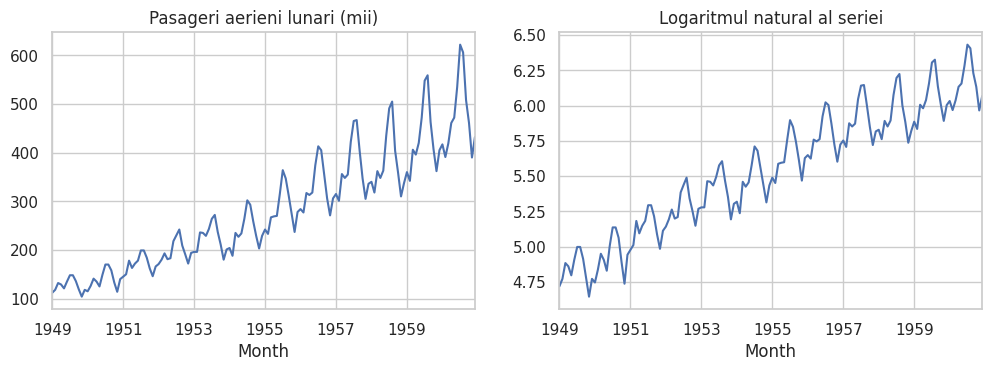

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ap.plot(ax=ax[0], title="Pasageri aerieni lunari (mii)")
np.log(ap).plot(ax=ax[1], title="Logaritmul natural al seriei")
plt.show()

> 🧠 **Ce învățăm.** Vârfurile anuale cresc pe măsură ce nivelul urcă, deci efectul sezonier este **proporțional** cu nivelul: o serie *multiplicativă*. După logaritm oscilațiile au înălțime constantă, iar seria poate fi tratată aditiv.

## 2.3  Descompunerea

`seasonal_decompose` estimează trendul cu o medie mobilă centrată pe o perioadă, mediază lună cu lună valorile fără trend pentru a obține tiparul sezonier și numește restul *reziduu*. **Singurul parametru care contează este `period`**: numărul de observații dintr-un sezon – **12** pentru date lunare cu tipar anual.

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose

dec = seasonal_decompose(ap, model="multiplicative", period=12)
seasonal_pattern = dec.seasonal.iloc[:12].round(3)
seasonal_pattern.index = seasonal_pattern.index.strftime("%b")
print("factor sezonier pe luni:", seasonal_pattern.to_dict())
print("abatere std. reziduu:", round(dec.resid.std(), 3))

factor sezonier pe luni: {'Jan': 0.91, 'Feb': 0.884, 'Mar': 1.007, 'Apr': 0.976, 'May': 0.981, 'Jun': 1.113, 'Jul': 1.227, 'Aug': 1.22, 'Sep': 1.06, 'Oct': 0.922, 'Nov': 0.801, 'Dec': 0.899}
abatere std. reziduu: 0.033


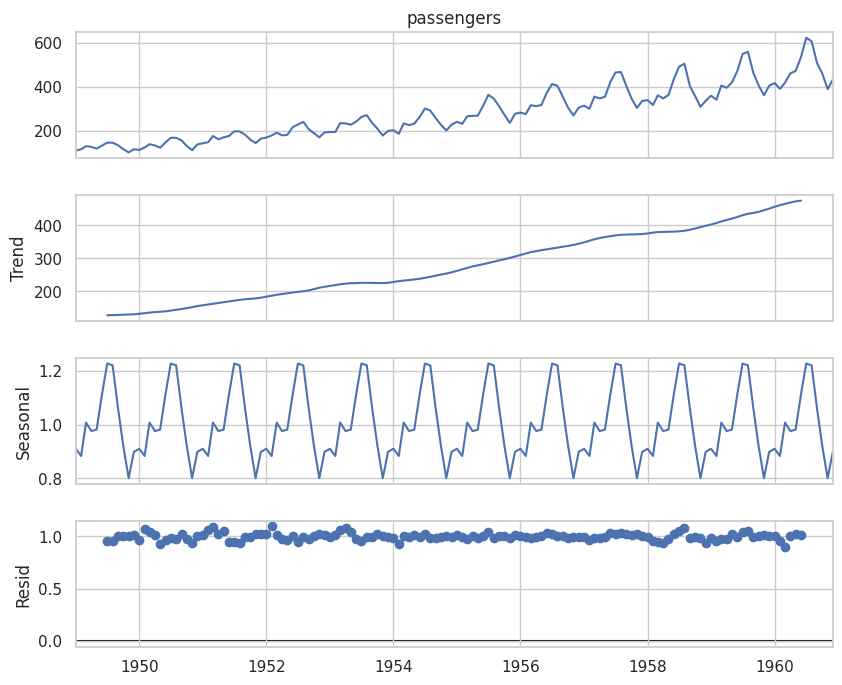

In [15]:
fig = dec.plot()
fig.set_size_inches(9, 7.5)
plt.show()

> 🧠 **Ce învățăm.** Iulie și august sunt cu **22–23 % peste** trend (factorii 1,23 și 1,22), noiembrie este cu **20 % sub** (0,80). Reziduul oscilează în jurul lui 1 cu o abatere standard de doar 3 %: trendul și sezonalitatea explică aproape totul. Primele și ultimele șase valori ale trendului lipsesc, deoarece o medie centrată pe 12 luni are nevoie de șase luni de fiecare parte.

> ⚠️ **O perioadă greșită dă un răspuns greșit – în tăcere.** Fișa anterioară folosea `period=30` pentru date **lunare**. Nu eșuează nimic: funcția mediază fericită fiecare a 30-a lună. Comparați reziduurile:

In [16]:
dec30 = seasonal_decompose(ap, model="multiplicative", period=30)
print("abatere std. reziduu, period = 12:", round(dec.resid.std(), 3))
print("abatere std. reziduu, period = 30:", round(dec30.resid.std(), 3), "  <- de aproape trei ori mai mare")

abatere std. reziduu, period = 12: 0.033
abatere std. reziduu, period = 30: 0.102   <- de aproape trei ori mai mare


**Aditiv sau multiplicativ?** Descompuneți în ambele moduri și comparați reziduurile: raportat la nivel, reziduul multiplicativ este aici mai mic (3 % față de 8,5 % la modelul aditiv). O alternativă modernă este **STL** (`statsmodels.tsa.seasonal.STL`), care permite tiparului sezonier să se schimbe lent și este robustă la valori aberante (`robust=True`); aplicați-o pe logaritmul seriei.

In [17]:
from statsmodels.tsa.seasonal import STL
stl = STL(np.log(ap), period=12, robust=True).fit()
strength_seasonal = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
strength_trend    = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
print(f"tăria sezonalității: {strength_seasonal:.2f}   tăria trendului: {strength_trend:.2f}   (1 = perfect)")

tăria sezonalității: 0.96   tăria trendului: 1.00   (1 = perfect)


## 2.4  Staționaritatea

O serie este (slab) **staționară** când media, varianța și autocorelația ei **nu depind de timp**. Zgomotul alb este staționar; o serie cu trend sau cu oscilații sezoniere în creștere nu este. Majoritatea modelelor clasice de prognoză (ARMA, ARIMA) presupun staționaritatea: pentru o serie staționară prognozele sunt mai fiabile, iar valorile întârziate sunt predictori aproape independenți.

> ℹ️ **Zgomot alb versus serie staționară.** Zgomotul alb este o serie staționară *specială*: valori independente, medie 0, niciun tipar. O serie staționară poate fi foarte bine predictibilă (poate fi puternic autocorelată) – doar că își păstrează același comportament statistic în timp.

### Cum o vedem: statistici glisante

Reprezentați grafic media glisantă și abaterea standard glisantă. Dacă derivă, seria nu este staționară.

### Cum o testăm: ADF și KPSS

Două **teste de rădăcină unitate** complementare se găsesc în `statsmodels.tsa.stattools`. Ele au ipoteze nule *opuse*, deci folosiți-le pe amândouă:

| Test | Ipoteza nulă H₀ | O valoare p mică (< 0,05) înseamnă |
|---|---|---|
| **ADF** (Dickey–Fuller augmentat) | seria are rădăcină unitate (este **nestaționară**) | respinge H₀ → dovadă pentru **staționaritate** |
| **KPSS** | seria este **staționară** (în jurul unui trend) | respinge H₀ → dovadă pentru **nestaționaritate** |

| ADF | KPSS | Concluzie |
|---|---|---|
| respinge H₀ | nu respinge | **staționară** |
| nu respinge | respinge H₀ | **nestaționară** → transformați |
| respinge | respinge | staționară în jurul trendului (eliminați trendul) sau caz mixt |
| nu respinge | nu respinge | dovezi insuficiente; priviți graficul |

In [18]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
warnings.filterwarnings("ignore", category=FutureWarning)     # statsmodels anunță o schimbare a tipului returnat de adfuller

def stationarity(x, name):
    x = x.dropna()
    p_adf = adfuller(x, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")           # kpss avertizează când valoarea p iese din tabelul său (0,01 ... 0,1)
        p_kpss = kpss(x, regression="c", nlags="auto")[1]
    verdict = "stationary" if (p_adf < 0.05 and p_kpss >= 0.05) else "NOT stationary" if (p_adf >= 0.05 and p_kpss < 0.05) else "unclear"
    return {"series": name, "ADF p": round(p_adf, 4), "KPSS p": round(p_kpss, 4), "verdict": verdict}

lp = np.log(ap)
rows = [stationarity(ap, "original"),
        stationarity(lp, "log"),
        stationarity(ap.diff(), "first difference"),
        stationarity(lp.diff(), "log + first difference"),
        stationarity(lp.diff().diff(12), "log + first + seasonal difference (12)")]
pd.DataFrame(rows).set_index("series")

,ADF p,KPSS p,verdict
series,,,
original,9.919e-01,0.01,NOT stationary
log,4.224e-01,0.01,NOT stationary
first difference,5.420e-02,0.10,unclear
log + first difference,7.110e-02,0.10,unclear
log + first + seasonal difference (12),2.000e-04,0.10,stationary


> 🧠 **Ce învățăm.** **O singură diferență nu este suficientă** – o greșeală ușor de făcut. Prima diferență elimină trendul, dar tiparul puternic de 12 luni rămâne: ADF rămâne peste 0,05. Abia după **diferența sezonieră** (valoarea minus valoarea de acum 12 luni) ambele teste concordă că seria este staționară. Un logaritm *înainte* de diferențiere stabilizează varianța. KPSS raportă 0,1 când tabelul său se termină: citiți „≥ 0,1”.

> 💡 **Nu diferențiați în exces.** Fiecare diferență în plus adaugă zgomot și poate crea autocorelație negativă artificială. Diferențiați doar până când testele și graficele spun *staționar*, de obicei o dată, plus o dată sezonier.

## 2.5  Autocorelația: ACF, PACF și graficele lag

**Autocorelația** este corelația unei serii cu propriul trecut. **ACF** la lag-ul *k* este corelația dintre *yₜ* și *yₜ₋ₖ*. **PACF** la lag-ul *k* este aceeași corelație după eliminarea efectului lag-urilor intermediare: este coeficientul lui *yₜ₋ₖ* într-o regresie a lui *yₜ* pe primele sale *k* lag-uri. Banda albastră este intervalul de încredere de 95 %: barele din afara ei sunt semnificative.

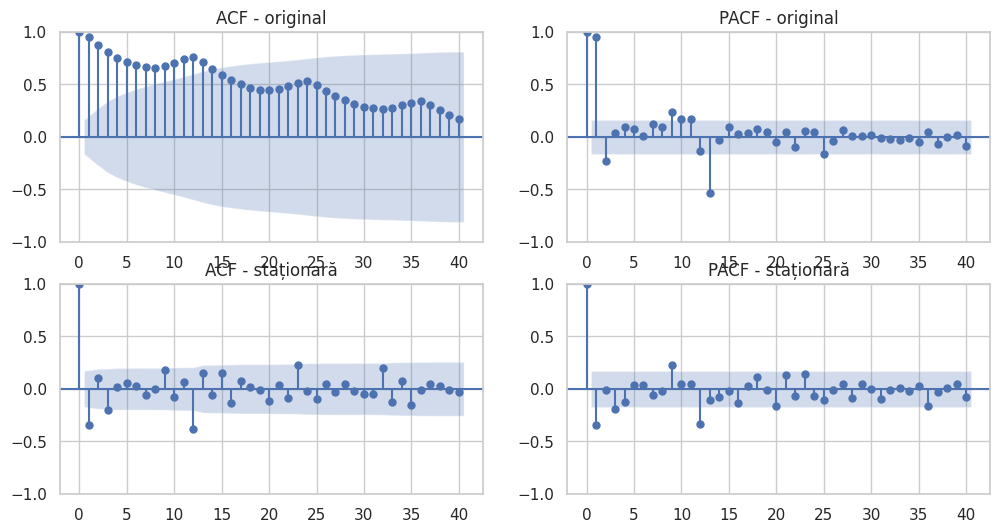

In [19]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
y = np.log(ap).diff().diff(12).dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(ap,  lags=40, ax=axes[0, 0], title="ACF - original");  plot_pacf(ap,  lags=40, ax=axes[0, 1], title="PACF - original", method="ywm")
plot_acf(y,   lags=40, ax=axes[1, 0], title="ACF - staționară"); plot_pacf(y,   lags=40, ax=axes[1, 1], title="PACF - staționară", method="ywm")
plt.show()

> 🧠 **Ce învățăm.** O **ACF cu descreștere lentă** este semnătura unui trend sau a nestaționarității. **Vârfurile la multipli de 12** dezvăluie sezonalitatea anuală. Pentru versiunea staționară rămân semnificative doar câteva lag-uri (1, 3 și 12): aceasta este ceea ce un model bun trebuie încă să explice, iar aceste lag-uri sunt punctul de plecare pentru alegerea ordinelor ARIMA în Laboratorul 6.

Un **grafic lag** reprezintă *yₜ* față de *yₜ₋ₖ*. O diagonală strânsă înseamnă dependență puternică; un nor fără formă înseamnă zgomot alb.

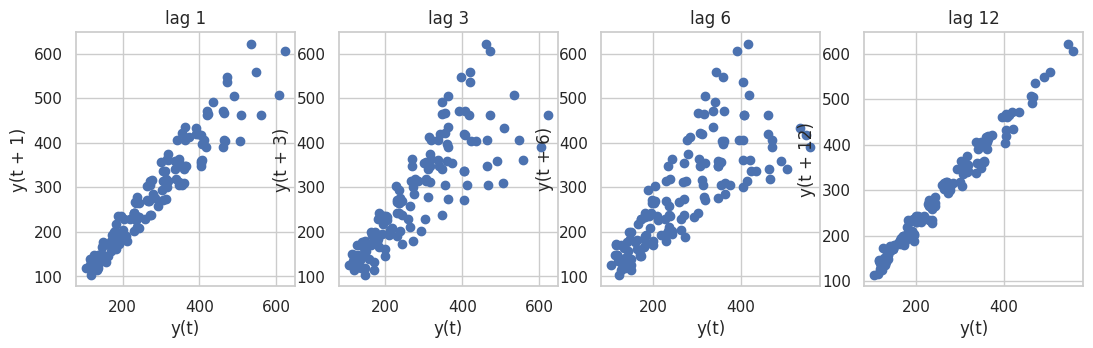

In [20]:
from pandas.plotting import lag_plot
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, lag in zip(axes, [1, 3, 6, 12]):
    lag_plot(ap, lag=lag, ax=ax); ax.set_title(f"lag {lag}")
plt.show()

## 2.6  Ajută o serie la prezicerea alteia? Cauzalitatea Granger

**Testul Granger** întreabă dacă valorile trecute ale lui *X* îmbunătățesc prognoza lui *Y* față de folosirea doar a trecutului lui *Y*. H₀: *X nu Granger-cauzează Y*; o valoare p mică o respinge. Cuvântul „cauzalitate” induce în eroare: înseamnă **precedență predictivă**, nu o cauză fizică. Două reguli fac testul util: (1) ambele serii trebuie să fie **staționare** – diferențiați-le mai întâi; (2) cauza candidată trebuie să fie o variabilă *diferită*, nu o caracteristică de calendar.

> ⚠️ **Ce a greșit?** Testăm dacă **numărul lunii** „cauzează” vânzările farmaceutice. Luna este o variabilă de calendar deterministă, deci testul redescoperă doar sezonalitatea, iar seriile nu fuseseră făcute staționare. O întrebare mai bună este fizică: precede **numărul de persoane** din biroul inteligent **nivelul de CO₂**?

In [21]:
from statsmodels.tsa.stattools import grangercausalitytests

hourly = office[["co2_ppm", "occupancy"]].resample("h").mean()
d = hourly.diff().dropna()                                   # diferențe: staționare (ADF p < 0,05 pentru ambele)
print("Valorile p ADF ale diferențelor:", {c: float(round(adfuller(d[c])[1], 4)) for c in d})

def granger_p(effect, cause, maxlag=3):
    res = grangercausalitytests(d[[effect, cause]], maxlag=maxlag)      # coloana 2 -> coloana 1
    return {lag: float(round(res[lag][0]["ssr_ftest"][1], 4)) for lag in range(1, maxlag + 1)}

print("ocupare -> CO2 :", granger_p("co2_ppm", "occupancy"))
print("CO2 -> ocupare :", granger_p("occupancy", "co2_ppm"))

Valorile p ADF ale diferențelor: {'co2_ppm': 0.0, 'occupancy': 0.0}
ocupare -> CO2 : {1: 0.0, 2: 0.0, 3: 0.0}
CO2 -> ocupare : {1: 0.1343, 2: 0.002, 3: 0.0005}


> 🧠 **Ce învățăm.** Testul este asimetric: **ocuparea trecută prezice CO₂ la fiecare lag cu p ≈ 0**, în timp ce CO₂ trecut **nu** prezice ocuparea la lag 1 (p ≈ 0,13) – ceea ce se potrivește cu fizica (oamenii expiră CO₂, nu invers). La lag-uri mai lungi și direcția inversă devine semnificativă, deoarece ambele serii au același ritm zilnic: acesta este motivul pentru care rezultatele Granger se citesc cu grijă și se privesc mereu datele. Testul nu dovedește niciodată un mecanism.

## 2.7  Netezirea

Netezirea reduce zgomotul pentru a arăta forma de fond sau oferă o versiune netezită a seriei ca trăsătură. Trei metode clasice:

| Metoda | Cum funcționează | Parametru | Atenție |
|---|---|---|---|
| **Medie mobilă** | media unei ferestre glisante (`rolling(w).mean()`) | fereastra `w` | o fereastră egală cu lungimea sezonului *anulează* sezonalitatea; marginile se pierd |
| **LOWESS / LOESS** | o regresie locală ponderată în jurul fiecărui punct (`statsmodels lowess`) | `frac`: fracția de puncte folosite | mai lent; un `frac` prea mare aplatizează schimbările reale |
| **Netezire exponențială** | medie ponderată cu ponderi care scad spre trecut (`ewm(alpha=…)`) | `alpha` (0–1) | rămâne în urma unui trend; `alpha` mare = netezire puțină |

In [22]:
from statsmodels.nonparametric.smoothers_lowess import lowess
ma12  = ap.rolling(12, center=True).mean()                                  # medie mobilă
low   = lowess(ap.values, np.arange(len(ap)), frac=0.4, return_sorted=False) # LOWESS
ewma  = ap.ewm(alpha=0.1).mean()                                            # netezire exponențială

> 🧠 **Ce învățăm.** Netezirea este un *filtru trece-jos*: păstrează partea lentă și elimină partea rapidă. Aceasta este puntea către următoarele două secțiuni: **vederea în frecvență** vă spune exact *ce* este lent și *ce* este rapid, iar Laboratorul 4 proiectează filtre adevărate.

# 3  Analiza în frecvență: de la DFT la STFT

## 3.1  De ce ne uităm la frecvențe?

Un grafic în timp al unui semnal complicat vă spune puțin: ritmurile nu se pot citi cu ochiul. **Transformata Fourier** rescrie orice semnal ca o **sumă de sinusuri și cosinusuri**; fiecare are o frecvență, o amplitudine și o fază. Graficul amplitudinii în funcție de frecvență – **spectrul** – răspunde la întrebarea „ce componente periodice conține semnalul și cât de puternice sunt?”. Folosim versiunea *discretă* (DFT), pentru semnale eșantionate.

Pentru *N* eșantioane *xₙ* DFT este  **X_k = Σ xₙ · e^(−2πi·kn/N)**,  k = 0 … N−1. Componenta de frecvență *k* corespunde la **k · fs / N** Hz, unde *fs* este frecvența de eșantionare. Spectrul unui semnal real este simetric: doar frecvențele până la **frecvența Nyquist fs/2** poartă informație; tot ce este mai rapid nu poate fi văzut deloc (apare ca o frecvență falsă, mai lentă – *aliere*).

## 3.2  DFT în cod și de ce există FFT

Luați trei sinusoide de 1, 4 și 7 Hz cu amplitudinile 3, 1 și 0,5, eșantionate la 100 Hz timp de o secundă. O implementare directă a formulei este un produs de matrice; **FFT** dă aceleași numere cu mult mai puține operații (N log N în loc de N²).

In [23]:
import time
from scipy.fft import fft, rfft, rfftfreq        # scipy.fft este modulul actual; scipy.fftpack este moștenit

sr = 100                                         # frecvența de eșantionare (Hz)
t = np.arange(0, 1, 1 / sr)
x = 3 * np.sin(2 * np.pi * 1 * t) + 1 * np.sin(2 * np.pi * 4 * t) + 0.5 * np.sin(2 * np.pi * 7 * t)

def dft(x):
    N = len(x); n = np.arange(N); k = n.reshape((N, 1))
    return np.exp(-2j * np.pi * k * n / N) @ x       # matricea exponențialelor complexe înmulțită cu semnalul

print("același rezultat ca FFT:", np.allclose(dft(x), fft(x)))

big = np.random.default_rng(0).normal(size=2000)     # un semnal de lungime 2000
for name, f in (("direct DFT", dft), ("FFT", fft)):
    t0 = time.perf_counter(); f(big); dt = time.perf_counter() - t0
    print(f"{name:10s}: {dt*1000:9.3f} ms")

același rezultat ca FFT: True


direct DFT:   212.055 ms
FFT       :     0.440 ms


**Normalizare.** `|X_k|` crește cu numărul de eșantioane. Pentru a citi amplitudinea unei componente în unitățile semnalului, împărțiți la *N* și, pentru spectrul unilateral, înmulțiți cu 2:

In [24]:
X = rfft(x)                                      # rfft: doar frecvențele nenegative ale unui semnal real
freq = rfftfreq(len(x), d=1 / sr)                # 0, 1, 2, ... 50 Hz
amplitude = np.abs(X) / len(x) * 2
peaks = {float(f): round(float(a), 2) for f, a in zip(freq, amplitude) if a > 0.01}
print("vârfuri (Hz: amplitudine):", peaks)

vârfuri (Hz: amplitudine): {1.0: 3.0, 4.0: 1.0, 7.0: 0.5}


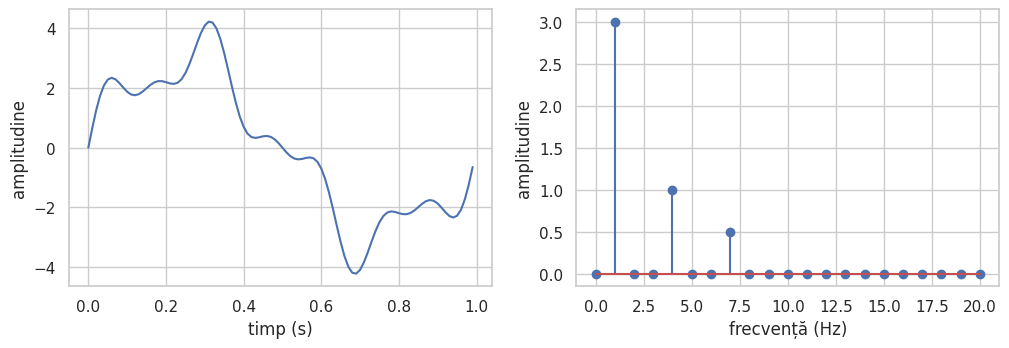

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(t, x); ax[0].set(xlabel="timp (s)", ylabel="amplitudine")
ax[1].stem(freq[:21], amplitude[:21]); ax[1].set(xlabel="frecvență (Hz)", ylabel="amplitudine")
plt.show()

> ⚠️ **Nu denumiți greșit lucrurile.** Până acum se importa `from scipy.fftpack import fft, ifft, fftfreq`. `scipy.fftpack` este un modul **moștenit** păstrat doar pentru cod vechi; folosiți `scipy.fft` (sau `numpy.fft`).

## 3.3  O greșeală de evitat: scurgerea spectrală

DFT presupune că segmentul înregistrat se repetă la nesfârșit. Dacă segmentul conține un **număr întreg de perioade** ale unei componente, repetiția este fără cusur, iar spectrul arată o singură linie curată. Altfel repetiția are un salt la margine, iar energia se **scurge** în componentele vecine. O fereastră care atenuează semnalul spre zero la margini (Hann, Hamming …) reduce scurgerea cu prețul unui vârf puțin mai lat.

In [26]:
from scipy import signal
fs = 100; t2 = np.arange(0, 2, 1 / fs)                       # 2 secunde
def peak_spectrum(freq_hz, window=None):
    s = np.sin(2 * np.pi * freq_hz * t2)
    w = np.ones(len(t2)) if window is None else signal.windows.hann(len(t2), sym=False)
    A = np.abs(rfft(s * w)) / w.sum() * 2
    return A
for label, f_, w in (("2,0 Hz, 4 perioade întregi", 2.0, None), ("2,3 Hz, 4,6 perioade", 2.3, None), ("2,3 Hz cu fereastră Hann", 2.3, "hann")):
    A = peak_spectrum(f_, w)
    print(f"{label:26s} vârf = {A.max():.2f}   energie în afara celor 3 componente mari = {1 - np.sort(A**2)[-3:].sum()/np.sum(A**2):.1%}")

2,0 Hz, 4 perioade întregi vârf = 1.00   energie în afara celor 3 componente mari = 0.0%
2,3 Hz, 4,6 perioade       vârf = 0.73   energie în afara celor 3 componente mari = 12.2%
2,3 Hz cu fereastră Hann   vârf = 0.90   energie în afara celor 3 componente mari = 1.1%


> 🧠 **Ce învățăm.** O sinusoidă perfectă de amplitudine 1 apare cu amplitudinea **1,00** când se potrivește în fereastră, dar doar **0,73** când nu (amplitudinea reală este „împrăștiată”). Ori de câte ori măsurați amplitudini: folosiți un segment cu un număr întreg de perioade sau aplicați o fereastră și **eliminați mai întâi media și trendul** – altfel componenta de frecvență zero domină imaginea.

## 3.4  Un semnal real: consumul de electricitate din California

Administrația americană pentru Informații Energetice (U.S. EIA) publică cererea orară a autorităților de echilibrare. Fișierul `930-data-export.csv` acoperă 28 septembrie – 28 octombrie 2024. Marcajele de timp arată ca `9/28/2024 12 a.m. PDT`: pandas nu poate ghici acest format, iar vechiul `parse_dates=[1]` producea sute de avertismente (și va deveni eroare). **Precizați explicit formatul.**

In [27]:
raw = pd.read_csv("930-data-export.csv")
stamp = (raw["Timestamp (Hour Ending)"].str.replace("a.m.", "AM", regex=False)
                                       .str.replace("p.m.", "PM", regex=False)
                                       .str.replace(" PDT", "", regex=False))
raw.index = pd.to_datetime(stamp, format="%m/%d/%Y %I %p")      # ora la care se încheie fiecare citire
demand = raw.drop(columns=["Region Code", "Timestamp (Hour Ending)"])
demand.columns = [c.split()[0] for c in demand.columns]           # BANC, CISO, IID, LDWP, TIDC
print(demand.shape, "| index orar regulat:", demand.index.to_series().diff().dropna().eq(pd.Timedelta("1h")).all())
print("rânduri cu cerere = 0:", {c: int((demand[c] == 0).sum()) for c in demand if (demand[c] == 0).any()})
demand.describe().loc[["mean", "min", "max"]].round(0)

(741, 5) | index orar regulat: True
rânduri cu cerere = 0: {'IID': 3}


,BANC,CISO,IID,LDWP,TIDC
mean,2023.0,26463.0,488.0,2579.0,351.0
min,1397.0,19728.0,0.0,848.0,232.0
max,3765.0,41205.0,1004.0,4482.0,629.0


Principala autoritate de echilibrare este **CISO** (rețeaua Californiei). Observați că `IID` are ore cu cerere zero: nu este o pană reală, ci o **problemă de calitate**, găsită cu aceleași reguli de interval ca în secțiunea 1.

Păstrăm **672 de ore = exact 4 săptămâni** (28 de zile), eliminăm trendul liniar și calculăm spectrul de amplitudine. Frecvențele se înțeleg mai bine ca **perioade**: perioada = 1 / frecvența.

In [28]:
x = signal.detrend(demand["CISO"].iloc[:672].to_numpy(float))        # 672 h = 28 de zile întregi = 4 săptămâni întregi
amp = np.abs(rfft(x)) / len(x) * 2
f_cph = rfftfreq(len(x), d=1.0)                                      # cicluri pe oră
period_h = 1 / f_cph[1:]
top = np.argsort(amp[1:])[::-1][:5]
print(pd.DataFrame({"perioadă (h)": period_h[top].round(1), "amplitudine (MWh)": amp[1:][top].round(0)}).to_string(index=False))

 perioadă (h)  amplitudine (MWh)
         24.0             3863.0
        168.0             2060.0
        672.0             1585.0
         12.0             1559.0
        336.0             1320.0


> 🧠 **Ce învățăm.** Cea mai puternică componentă are perioada de **24 h** (ciclul zilnic, amplitudine ≈ 3 900 MWh), urmată de **168 h** (ciclul săptămânal, ≈ 2 060 MWh – zile lucrătoare față de weekend). Urmează componentele de **672 h** și **336 h** (≈ 1 590 și 1 320 MWh): scăderea lentă, curbată, a lunii, pe care eliminarea unei drepte nu o scoate complet. Linia de **12 h** (≈ 1 560 MWh) este o armonică: curba zilnică nu este o sinusoidă pură, ci are un vârf de dimineață și unul de seară. Perioada de 84 h din fișa veche este armonica a 2-a a săptămânii; este mică. FFT a transformat un grafic „greu de citit” într-o listă de **ritmuri umane**.

## 3.5  Filtrarea cu FFT: ideea și limita ei

Anularea unor coeficienți FFT și transformarea înapoi este cel mai simplu filtru: un **trece-sus** păstrează frecvențele peste o frecvență de tăiere, un **trece-jos** pe cele de sub ea, un **trece-bandă** pe cele dintre două frecvențe. Aici un trece-sus la 6 Hz aplicat semnalului de 1–4–7 Hz păstrează doar componenta de 7 Hz.

In [29]:
from scipy.fft import ifft, fftfreq
X = fft(x_sig := 3*np.sin(2*np.pi*1*t) + np.sin(2*np.pi*4*t) + 0.5*np.sin(2*np.pi*7*t))
f = fftfreq(len(x_sig), d=1 / sr)                # frecvențe pozitive și negative
X_hp = X.copy(); X_hp[np.abs(f) < 6] = 0         # trece-sus „perete de cărămidă”, tăiere la 6 Hz
filtered = ifft(X_hp).real
print("amplitudinea rămasă a sinusoidei de 7 Hz:", round(float(np.abs(rfft(filtered)).max() / len(filtered) * 2), 2))
print("cea mai mare diferență față de 0,5·sin(2π·7t) pur:", round(float(np.abs(filtered - 0.5*np.sin(2*np.pi*7*t)).max()), 12))

amplitudinea rămasă a sinusoidei de 7 Hz: 0.5
cea mai mare diferență față de 0,5·sin(2π·7t) pur: 0.0


> ⚠️ **Acest filtru „perete de cărămidă” este un instrument didactic, nu un proiect.** Funcționează perfect aici deoarece fiecare componentă se află **exact** pe un coeficient FFT. Pentru semnale reale tăierea abruptă face ca rezultatul să **oscileze** (*fenomenul Gibbs*) și tratează segmentul ca periodic. Figura arată o treaptă trecută printr-un trece-jos ideal: apar ondulații înainte și după salt. Filtrele proiectate corect (Butterworth, Chebyshev, FIR, median, wavelet) și filtrarea cu fază zero prin `sosfiltfilt` sunt subiectul **Laboratorului 4**.

## 3.6  Frecvențele în timp: transformata Fourier pe termen scurt

FFT dă frecvențele **întregii** înregistrări și pierde *când* apar ele. Un semnal a cărui frecvență se schimbă – o baleiere, vorbirea, o vibrație care începe la un moment dat – are nevoie de o vedere **timp–frecvență**. **Transformata Fourier pe termen scurt (STFT)** taie semnalul în bucăți scurte, suprapuse și ferestruite, calculează FFT pentru fiecare bucată și așază spectrele unul lângă altul: rezultatul este **spectrograma**.

Există un compromis (*principiul incertitudinii*): o fereastră **scurtă** localizează evenimentele în timp, dar tulbură frecvența; o fereastră **lungă** rezolvă frecvența, dar tulbură timpul. Semnal de test: un chirp care baleiază de la 20 la 200 Hz în 4 s, plus un ton de 60 Hz care începe la 2,5 s.

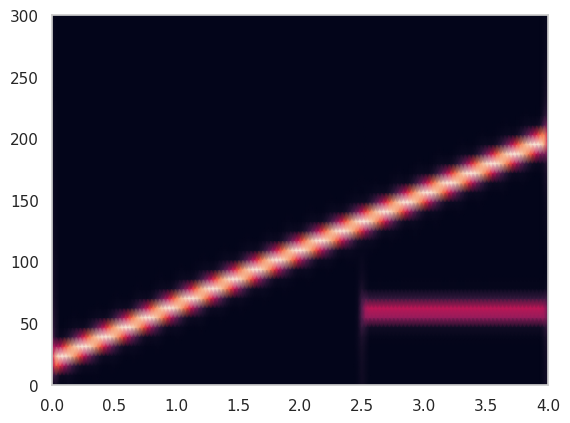

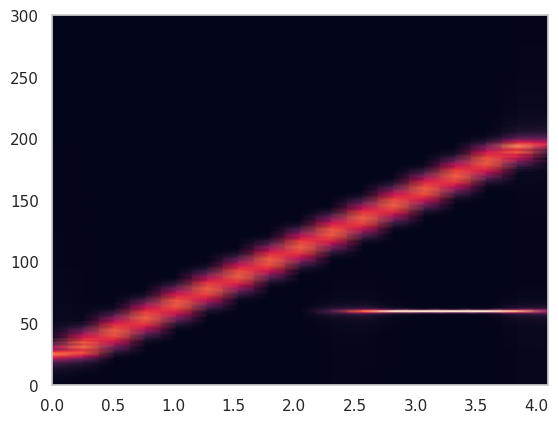

In [30]:
from scipy import signal
fs = 1000; t = np.arange(0, 4, 1 / fs)
x = signal.chirp(t, f0=20, f1=200, t1=4, method="linear") + 0.5 * np.sin(2 * np.pi * 60 * t) * (t > 2.5)

for nper in (128, 1024):                                           # lungimea ferestrei în eșantioane
    f_, t_, Z = signal.stft(x, fs, window="hann", nperseg=nper, noverlap=nper * 3 // 4)
    plt.figure(); plt.pcolormesh(t_, f_, np.abs(Z), shading="gouraud"); plt.ylim(0, 300)

Un exemplu real: STFT a cererii de electricitate cu o fereastră de o săptămână (168 h, pas de 24 h). Linia zilnică (1 ciclu/zi) și armonicile ei (2, 3 cicluri/zi) se văd toată luna și sunt cele mai puternice în primele două săptămâni, când cererea este mare; componenta foarte lentă de jos este deriva lunii.

> ℹ️ **`scipy.signal.spectrogram` sau `stft`?.** `signal.spectrogram` returnează direct puterea și este comod pentru grafice; `signal.stft` returnează coeficienții complecși (se poate inversa cu `istft`). În SciPy recent noua clasă `signal.ShortTimeFFT` este interfața recomandată, iar `stft`/`spectrogram` sunt marcate *legacy*; ele încă funcționează și dau aceleași imagini. Transformata wavelet (Laboratorul 5) este pasul următor când o fereastră fixă nu mai este suficientă.

# 4  Rezumat și liste de verificare

| Subiect | Instrument | De reținut |
|---|---|---|
| reguli de calitate | `isin`, `to_numeric(errors="coerce")`, `str.fullmatch`, join cu o listă de referință | potrivire exactă, nu `contains`; verificați mai multe coloane împreună; păstrați un **raport** |
| completitudine | `isna()`, diferența de mulțimi a categoriilor | un fișier acurat poate fi totuși incomplet |
| descompunere | `seasonal_decompose(period=…)`, `STL` | **period = observații pe sezon** (12 pentru date lunare); multiplicativ dacă oscilațiile cresc |
| staționaritate | ADF + KPSS, statistici glisante | ipoteze nule opuse; o singură diferență poate să nu fie suficientă |
| autocorelație | ACF, PACF, grafic lag | descreștere lentă = trend; vârfuri la multipli ai perioadei = sezonalitate |
| Granger | `grangercausalitytests` | serii staționare, variabile diferite; este cauzalitate *predictivă*, nu fizică |
| spectru | `scipy.fft.rfft`, `rfftfreq` | împărțiți la N, ×2; eliminați media și trendul; perioade întregi sau o fereastră |
| timp–frecvență | `signal.stft` | fereastră scurtă = detaliu în timp, fereastră lungă = detaliu în frecvență |

### Lecturi suplimentare

* [GeeksforGeeks – Time Series Analysis and Forecasting](https://www.geeksforgeeks.org/data-analysis/time-series-analysis-and-forecasting/)
* [statsmodels – Time series analysis](https://www.statsmodels.org/stable/tsa.html) · [SciPy – Discrete Fourier transforms (`scipy.fft`)](https://docs.scipy.org/doc/scipy/tutorial/fft.html) · [SciPy – Signal processing](https://docs.scipy.org/doc/scipy/tutorial/signal.html)
* R. Hyndman, G. Athanasopoulos – *Forecasting: Principles and Practice* (carte online gratuită, capitolele despre descompunere și staționaritate)
* U.S. Energy Information Administration – [Hourly Electric Grid Monitor](https://www.eia.gov/electricity/gridmonitor/)


## Gata — și acum?
1. Schimbați parametrii (`period`, dimensiunile ferestrelor, frecvențele de tăiere) și urmăriți cum reacționează figurile.
2. Deschideți `Lab3_Exercitii.ipynb`: un fișier de anunțuri deteriorat, vânzări de farmacie și spectre de electricitate, fiecare cu autoverificări.
3. Filtrele de eliminare a zgomotului și reducerea dimensionalității urmează în Laboratorul 4.
